In [64]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from typing import Iterable, List, Tuple

from sklearn.model_selection import train_test_split

In [65]:
data = pd.read_csv('data/boston_house_prices.csv')
data.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


## Описание набора данных:

Boston Housing содержит данные, собранные Службой переписи населения США (англ. U.S Census Service), касающиеся недвижимости в районах Бостона. Набор данных состоит из 13 признаков и 506 строк и также предоставляет такую информацию, как уровень преступности (CRIM), ставка налога на недвижимость (TAX), возраст людей, которым принадлежит дом (AGE), соотношение числа учащихся и преподавателей в районе (PTRATIO) и другие. Данный набор данных используется для предсказания следующих целевых переменных: средняя стоимость дома (MEDV) и уровень закиси азота (NOX).

In [66]:
feature_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']

X = pd.DataFrame(data, columns=feature_names, index=range(len(data)))
y = pd.DataFrame(data, columns=['MEDV'], index=range(len(data)))

X['target'] = y

In [67]:
X_train, X_test = train_test_split(X, test_size=0.25, random_state=13)

#### Задание 1: Реализуйте подсчет критерия ошибки. Для этого реализуйте функции для подсчета значения критерия информативности, а также для разбиения вершины.

In [68]:
def H(R: np.array) -> float:
    """Вычислить критерий информативности для фиксированного набора объектов R.
    Предполагается, что последний столбец содержит целевое значение
    """
    y = R['target'][:]
    return np.mean((y - y.mean())**2)


def split_node(R: np.array, feature: str, t: float) -> Iterable[np.array]:
    """
    Разделить фиксированный набор объектов R по признаку feature с пороговым значением t
    """
    mask = R[feature][:] <= t
    R_l = R[mask]
    R_r = R[~mask]
    return R_l, R_r


def Q(R: np.array, feature: str, t: float) -> float:
    """
    Вычислить функционал качества для заданных параметров разделения
    """
    R_l, R_r = split_node(R, feature, t)
    n = len(R)
    if n == 0:
        return 0
    return (len(R_l) / n) * H(R_l) + (len(R_r) / n) * H(R_r)

#### Задание 2: Переберите все возможные разбиения обучающей выборки по одному из признаков и постройте график критерия ошибки в зависимости от значения порога.

In [69]:
SELECTED_FEATURE = 'TAX'
min_feature = X_train[SELECTED_FEATURE].min()
max_feature = X_train[SELECTED_FEATURE].max()

thresholds = [x for x in range(min_feature, max_feature+1)]
Q_s = [Q(X, SELECTED_FEATURE, td) for td in thresholds]

Text(0.5, 1.0, 'Relation between threshold and MSE for "TAX"')

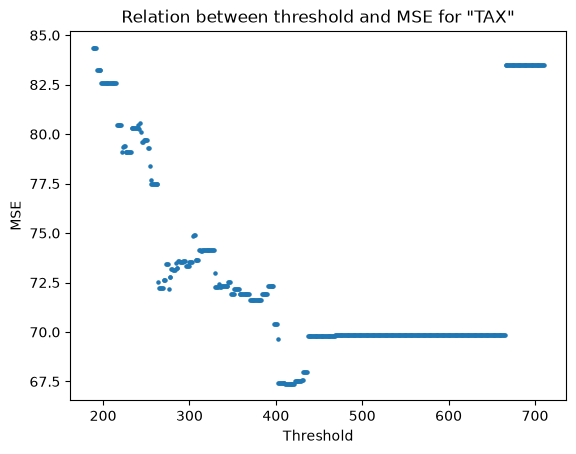

In [70]:
plt.scatter(thresholds, Q_s, s=5)
plt.xlabel('Threshold')
plt.ylabel('MSE')
plt.title('Relation between threshold and MSE for "TAX"')

#### Задание 3: Напишите функцию, находящую оптимальное разбиение данной вершины по данному признаку.

In [71]:
def get_optimal_split(R: pd.DataFrame, feature: str) -> Tuple[float, float]:

    u = np.unique(R[feature].dropna().to_numpy())

    if len(u) < 2:
        return np.nan, np.inf

    thresholds = (u[:-1] + u[1:]) / 2
    Q_s = np.array([Q(R, feature, t) for t in thresholds])

    best_id = np.nanargmin(Q_s)
    return thresholds[best_id], Q_s[best_id]

#### Задание 4: Для первого разбиения найдите признак, показывающий наилучшее качество. Каков порог разбиения и значение качества? Постройте график критерия ошибки для данного признака в зависимости от значения порога.

In [72]:
cols = np.array(X_train.columns)
mses = []
ths = []
for col in cols:
    th, q = get_optimal_split(X_train, col)
    mses.append(q)
    ths.append(th)

In [73]:
mses

[np.float64(67.39254669771015),
 np.float64(69.34076590623248),
 np.float64(60.347526495859015),
 np.float64(78.93996784223368),
 np.float64(64.56169489613504),
 np.float64(46.42614228882214),
 np.float64(70.88908265552672),
 np.float64(71.40506193171146),
 np.float64(71.1383664054875),
 np.float64(67.3415667505267),
 np.float64(63.055920087579615),
 np.float64(72.81105281163394),
 np.float64(46.448000769349775),
 np.float64(30.862667000813644)]

Text(0.5, 1.0, 'Relation between threshold and MSE for "TAX"')

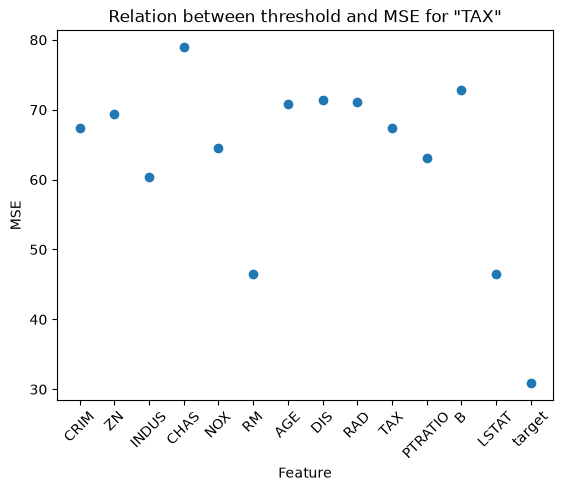

In [74]:
plt.scatter(range(len(cols)), mses)
plt.xlabel('Feature')
plt.ylabel('MSE')
plt.xticks(range(len(cols)), cols, rotation=45)
plt.title('Relation between threshold and MSE for "TAX"')

In [75]:
ths[5]

np.float64(6.803)

#### Задание 5: Изобразите разбиение визуально. Для этого постройте диаграмму рассеяния целевой переменной в зависимости от значения входного признака. Далее изобразите вертикальную линию, соответствующую порогу разбиения.

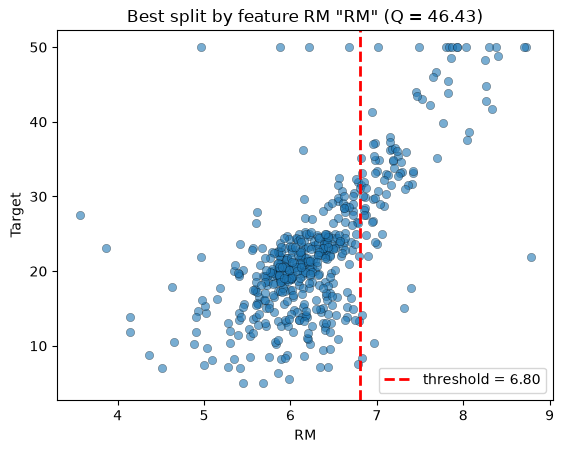

In [76]:
best = int(np.argmin(mses[:-1]))
best_feature = cols[best]
best_threshold = ths[best]

x = X[best_feature]
y = X['target']

plt.scatter(x, y, alpha=0.6, edgecolor='k', linewidth=0.3)
plt.axvline(best_threshold, color='r', linestyle='--', linewidth=2,
            label=f'threshold = {best_threshold:.2f}')
plt.xlabel(best_feature)
plt.ylabel('Target')
plt.title(f'Best split by feature {best_feature} "{best_feature}" (Q = {mses[best]:.2f})')
plt.legend()
plt.show()

#### Задание 6: Постройте модель обучения с помощью библиотеки модуля Decision Tree.

In [77]:
X_train, y_train = X_train.drop(columns=['target']), X_train['target']
X_test, y_test = X_test.drop(columns=['target']), X_test['target']

In [89]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import root_mean_squared_error
from sklearn.dummy import DummyRegressor

tree = DecisionTreeRegressor(max_depth=6, random_state=42)
tree.fit(X_train, y_train)

dummy_reg = DummyRegressor(strategy='mean')
dummy_reg.fit(X_train, y_train)
dummy_pred = dummy_reg.predict(X_test)

predictions = tree.predict(X_test)
root_mean_squared_error(y_test, predictions), root_mean_squared_error(y_test, dummy_pred)

(3.694492189559881, 9.506981049172166)